# Day 31 — What Machine Learning Is
### Machine Learning · Module 3 · Topics 3.1 + 3.2

**Prepared & presented by Srinivasa Sai Chava**  ·  Boston University

---

**Session length:** 2 hours · 90 min concepts + 30 min practice

| # | What we cover | Time |
|---|---|---|
| 1 | What machine learning is, and the vocabulary | 20 min |
| 2 | The three kinds of learning | 25 min |
| 3 | How a project runs — the pipeline and train/test | 15 min |
| 4 | What a feature is, and why models cannot read words | 10 min |
| 5 | **Encoding categorical data** | 20 min |
| 6 | **Practice notebook (separate file)** | 30 min |

---

## Read this first

**Nothing in this module assumes you have seen machine learning before.** Every term is
defined the first time it is used. If a word goes past that you do not know, that is a bug
in the notes, not in you — say so.

Everything below runs. Run every cell yourself; change the numbers and run them again. That
is the fastest way to find out what each line actually does.

### Four things you will see today

1. A model will **learn a rule in front of you**, and there will be no magic in it.
2. A model will score **100% on its homework** and then do **worse than guessing** on the exam.
3. Writing one word as a number the wrong way will **double a model's error**.
4. A model will report a **positive score on data containing nothing at all**, because of a
   single line in the wrong order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score
import warnings
warnings.simplefilter("ignore")

plt.rcParams["figure.figsize"] = (8, 3.2)
print("pandas", pd.__version__, "| numpy", np.__version__,
      "| scikit-learn", __import__("sklearn").__version__)

pandas 2.2.3 | numpy 1.26.4 | scikit-learn 1.6.1


---
# 1 · What machine learning is

## 1.1 · ⭐ The whole idea

Every program you have written in this course so far works like this:

> **RULES  +  DATA  →  ANSWERS**
>
> You write the rule (`if area > 2000: price = ...`), feed it data, and get answers out.

Machine learning swaps two of those boxes around:

> **DATA  +  ANSWERS  →  RULES**
>
> You feed in examples where you already know the right answer, and the computer gives you
> back the rule.

That swap is the entire definition. You use it when **you do not know the rule** — which is
almost always true for anything interesting. Nobody can write down the formula that turns a
photograph into "cat", but we can collect a million labelled photographs.

## 1.2 · A first example, start to finish

We have 60 houses we have already sold. For each one we know **how big it was** and **what
it sold for**. We want to price a new one.

In [2]:
rng = np.random.default_rng(3101)
n = 60
area  = rng.uniform(600, 2400, n).round(0)          # square feet
price = (45 + 0.115*area + rng.normal(0, 18, n)).round(1)   # thousands of dollars

houses = pd.DataFrame({"area": area, "price": price})
print(houses.head())
print("\n60 houses, 2 columns.")

     area  price
0  1756.0  245.1
1  1079.0  157.1
2  1136.0  186.3
3   621.0   92.0
4  1162.0  183.0

60 houses, 2 columns.


In [3]:
# TRAIN the model. Two lines. This is the whole of "machine learning" here.
model = LinearRegression()
model.fit(houses[["area"]], houses["price"])

print("The rule the computer found:")
print(f"   price = {model.intercept_:.2f} + {model.coef_[0]:.4f} * area")
print()
print("Nobody wrote that. It was found by looking at the 60 examples.")

The rule the computer found:
   price = 36.90 + 0.1194 * area

Nobody wrote that. It was found by looking at the 60 examples.


In [4]:
# Now USE it on a house we have never seen
new_house = 1500
predicted = model.predict([[new_house]])[0]
print(f"A {new_house} sq ft house we have never seen -> ${predicted:.1f}k")

A 1500 sq ft house we have never seen -> $216.0k


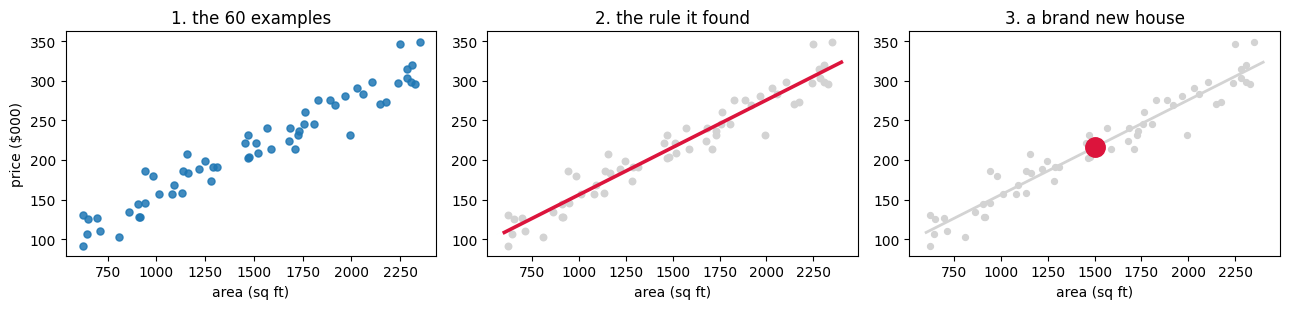

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
g = np.linspace(600, 2400, 10)

axes[0].scatter(area, price, s=26, alpha=.85)
axes[0].set_title("1. the 60 examples")

axes[1].scatter(area, price, s=22, color="lightgrey")
axes[1].plot(g, model.predict(g.reshape(-1, 1)), color="crimson", lw=2.6)
axes[1].set_title("2. the rule it found")

axes[2].scatter(area, price, s=18, color="lightgrey")
axes[2].plot(g, model.predict(g.reshape(-1, 1)), color="lightgrey", lw=2)
axes[2].plot([new_house], [predicted], "o", color="crimson", ms=14)
axes[2].set_title("3. a brand new house")

for a_ in axes:
    a_.set_xlabel("area (sq ft)")
axes[0].set_ylabel("price ($000)")
plt.tight_layout(); plt.show()

## 1.3 · The five words you need

Look at a fuller version of the table and name its parts. These five words appear in every
sentence anyone says about machine learning, so they are worth getting right now.

In [6]:
demo = pd.DataFrame({
    "area":     [1450, 890, 2100, 1200],
    "bedrooms": [3, 2, 4, 3],
    "city":     ["Boston", "Austin", "Miami", "Denver"],
    "age":      [12, 30, 5, 22],
    "price":    [289, 151, 372, 198],
})
print(demo)

   area  bedrooms    city  age  price
0  1450         3  Boston   12    289
1   890         2  Austin   30    151
2  2100         4   Miami    5    372
3  1200         3  Denver   22    198


| word | what it means here |
|---|---|
| **sample** | one **row** — one house. Also called an observation, an instance, or an example. |
| **feature** | one **input column**: `area`, `bedrooms`, `city`, `age`. Written **X**. |
| **label** | the **answer column** we want to predict: `price`. Written **y**. Also called the target. |
| **model** | the rule, once it has been found |
| **training** | the act of finding the rule — the `.fit()` call |

By convention, `X` is the features (capital, because it is a table) and `y` is the label
(lowercase, because it is a single column). You will see this everywhere.

In [7]:
X = demo[["area", "bedrooms", "age"]]    # features (we leave 'city' out for now - section 5)
y = demo["price"]                        # label

print("X shape:", X.shape, " -> 4 samples, 3 features")
print("y shape:", y.shape, " -> 4 answers")

X shape: (4, 3)  -> 4 samples, 3 features
y shape: (4,)  -> 4 answers


## 1.4 · ⭐ What "learning" actually means

This is the part that sounds mysterious and is not. A model is:

1. a formula with some **numbers in it you can change** (here, the slope and the intercept)
2. a way of **measuring how wrong** the current numbers are
3. a way of **changing them to be less wrong**

Let us do all three by hand. We will fix the intercept at 45 and hunt for the best slope.

In [8]:
def mean_squared_error_for(slope, intercept=45):
    """How wrong is this rule? Average of (actual - predicted) squared."""
    predicted = intercept + slope*area
    return ((price - predicted)**2).mean()

for s in [0.05, 0.08, 0.115, 0.15, 0.20]:
    print(f"   slope {s:.3f}  ->  error {mean_squared_error_for(s):9.1f}")

   slope 0.050  ->  error   10753.1
   slope 0.080  ->  error    3283.3
   slope 0.115  ->  error     284.0
   slope 0.150  ->  error    3439.7
   slope 0.200  ->  error   18625.2


In [9]:
# Try every slope between 0.02 and 0.26 and keep the best one
candidates = np.arange(0.02, 0.26, 0.002)
errors = np.array([mean_squared_error_for(s) for s in candidates])
best = candidates[errors.argmin()]

print(f"best slope found by brute force: {best:.3f}")
print(f"smallest error:                  {errors.min():.1f}")
print(f"what sklearn found earlier:      {model.coef_[0]:.3f}")
print()
print("Not identical, and that is expected: we held the intercept at 45,")
print(f"while sklearn was free to move it (it chose {model.intercept_:.2f}).")
print("Fix one number and the best value of the other shifts.")

best slope found by brute force: 0.114
smallest error:                  284.2
what sklearn found earlier:      0.119

Not identical, and that is expected: we held the intercept at 45,
while sklearn was free to move it (it chose 36.90).
Fix one number and the best value of the other shifts.


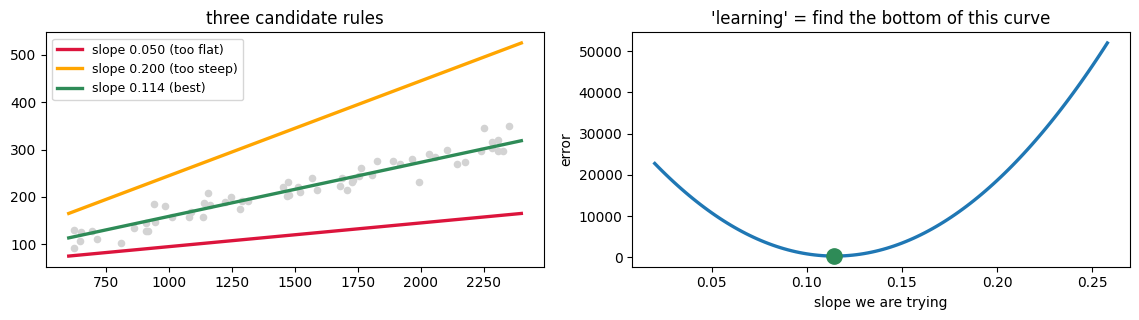

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))
axes[0].scatter(area, price, s=20, color="lightgrey")
for s, c, lab in [(0.05, "crimson", "too flat"), (0.20, "orange", "too steep"),
                  (best, "seagreen", "best")]:
    axes[0].plot(g, 45 + s*g, color=c, lw=2.4, label=f"slope {s:.3f} ({lab})")
axes[0].legend(fontsize=9); axes[0].set_title("three candidate rules")

axes[1].plot(candidates, errors, lw=2.4)
axes[1].plot([best], [errors.min()], "o", color="seagreen", ms=11)
axes[1].set_xlabel("slope we are trying"); axes[1].set_ylabel("error")
axes[1].set_title("'learning' = find the bottom of this curve")
plt.tight_layout(); plt.show()

That curve is the whole of machine learning in one picture.

- Every point on it is **one possible rule**.
- Its height is **how wrong that rule is**.
- Training means **walking downhill to the bottom**.

Here we found the bottom by trying 120 slopes. That works when there is one number to find.
A real model has thousands or millions of numbers, and trying them all is impossible — so
instead you compute which direction is downhill and take a step. That method is called
**gradient descent**, and we derive it line by line on Day 35.

Nothing else changes. It is still: *pick numbers, measure the error, change the numbers.*

---
# 2 · The three kinds of learning

The three kinds are told apart by **one question: what feedback does the learner get?**

| kind | feedback it gets |
|---|---|
| **Supervised** | the correct answer for every training row |
| **Unsupervised** | nothing at all |
| **Reinforcement** | not the answer, but a reward or penalty after it acts |

## 2.1 · Supervised learning

Every row comes with its right answer attached. The model learns to reproduce the answer
key, then applies it to rows it has never seen. **This is roughly 90% of machine learning in
industry**, and almost all of this module.

It splits in two, and the split is decided by one thing only: **the type of the label**.

In [11]:
# REGRESSION - the label is a number
print("REGRESSION:  label = price      ->", houses.price.head(3).tolist(), "... any value on a scale")

# CLASSIFICATION - the label is a category
emails = pd.DataFrame({"n_links": [0, 7, 1, 12], "has_offer": [0, 1, 0, 1],
                       "is_spam":  ["no", "yes", "no", "yes"]})
print("CLASSIFICATION: label = is_spam ->", emails.is_spam.tolist(), "... one of a fixed list")

REGRESSION:  label = price      -> [245.1, 157.1, 186.3] ... any value on a scale
CLASSIFICATION: label = is_spam -> ['no', 'yes', 'no', 'yes'] ... one of a fixed list


| | regression | classification |
|---|---|---|
| the label is | a number on a scale | one of a fixed set of options |
| examples | house price, tomorrow's temperature, units sold, blood pressure | spam / not spam, which of 10 digits, will this customer leave, malignant / benign |
| typical score | mean absolute error, R² | accuracy, precision, recall |

**The test:** look at the label column. Numbers on a scale → regression. A fixed list of
options → classification. Nothing else decides it.

## 2.2 · Unsupervised learning

**No answers at all.** You hand over a table and ask the model to find structure that was
already in it. Two main jobs.

K-Means was given NO labels. It found 3 groups.
group sizes: [60 60 60]


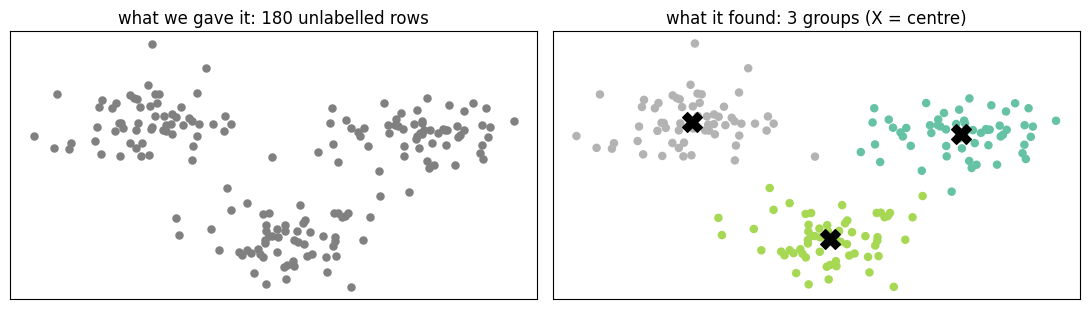

In [12]:
# CLUSTERING - group the rows
from sklearn.cluster import KMeans
rng2 = np.random.default_rng(77)
pts = np.vstack([rng2.normal([-1.6, 1.3], .55, (60, 2)),
                 rng2.normal([1.7, 1.1], .55, (60, 2)),
                 rng2.normal([0.0, -1.7], .55, (60, 2))])

km = KMeans(n_clusters=3, n_init=10, random_state=0).fit(pts)
print("K-Means was given NO labels. It found", len(set(km.labels_)), "groups.")
print("group sizes:", np.bincount(km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(pts[:, 0], pts[:, 1], s=26, color="grey")
axes[0].set_title("what we gave it: 180 unlabelled rows")
axes[1].scatter(pts[:, 0], pts[:, 1], s=26, c=km.labels_, cmap="Set2")
axes[1].scatter(*km.cluster_centers_.T, marker="X", s=200, c="black")
axes[1].set_title("what it found: 3 groups (X = centre)")
for a_ in axes: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

Notice what is **missing**: there is no accuracy score here. Nobody said there were three
groups, and nobody can tell you the grouping is "correct" — because there is nothing to be
correct against. You look at the groups, decide whether they mean something, and name them
yourself.

That is the hardest part of unsupervised learning, and it is a judgement call, not a metric.

In [13]:
# DIMENSIONALITY REDUCTION - shrink the columns
from sklearn.decomposition import PCA
rng3 = np.random.default_rng(5)
th = np.pi/5
base = rng3.normal(0, 1, (160, 2)) * np.array([2.4, 0.45])
R = np.array([[np.cos(th), -np.sin(th)], [np.sin(th), np.cos(th)]])
cloud = base @ R.T

p = PCA(n_components=2).fit(cloud)
print("variance explained by each direction:", p.explained_variance_ratio_.round(3))
print(f"-> the first direction alone carries {p.explained_variance_ratio_[0]:.1%} of the information")
print("   so 2 columns could become 1 with very little loss")

variance explained by each direction: [0.962 0.038]
-> the first direction alone carries 96.2% of the information
   so 2 columns could become 1 with very little loss


With 2 columns that is a toy. With 80 survey questions that mostly measure three underlying
attitudes, it is the difference between a model that works and one that does not.

## 2.3 · Reinforcement learning

**No answers, but the world keeps score.** The learner acts, and gets back a reward or a
penalty. Think of learning to ride a bicycle: nobody gave you a table of handlebar angles;
you fell over (penalty), tried again, stayed up (reward), and adjusted.

| piece | what it is |
|---|---|
| **agent** | the learner — the thing making choices |
| **environment** | the world it acts in |
| **action** | what it chooses to do |
| **reward** | the number the world gives back |

Where you have met it: game-playing engines that beat world champions at Go and chess · a
robot arm learning to grasp · warehouse robots routing themselves · recommendation feeds
that watch whether you keep scrolling · data-centre cooling policies.

⚠️ RL is **not covered further in this course**, so do not wait for it. It needs an
environment you can simulate millions of times cheaply, and most business problems do not
have one. It is on this slide so you can recognise it and know it is a different thing.

## 2.4 · Which kind is my problem?

One question decides it: **do I have the right answers for the rows I already have?**

| What you have | What you want | It is… |
|---|---|---|
| rows **with** the right answer, a number | predict that number | supervised · **regression** |
| rows **with** the right answer, a category | predict that category | supervised · **classification** |
| rows with **no** answers | find natural groups | unsupervised · **clustering** |
| rows with **no** answers, too many columns | a simpler description | unsupervised · **dim. reduction** |
| no fixed data — a world you can act in | a good policy over time | **reinforcement** |

⚠️ **The most common beginner mistake:** having no labels, wanting a prediction anyway, and
reaching for a supervised model. If nobody has written down the right answer for your
existing rows, no supervised algorithm can help you. *Getting the labels is the project.*

---
# 3 · How a project actually runs

## 3.1 · The eight steps

| | step | |
|---|---|---|
| 1 | get the data | |
| 2 | clean it | Module 1 |
| 3 | **encode and scale** | ← **today** |
| 4 | **split into train and test** | ← **today** |
| 5 | train the model | the rest of Module 3 |
| 6 | evaluate on the **test** set | |
| 7 | tune, and go back to step 3 | |
| 8 | deploy | |

⚠️ Steps 1–3 are routinely **most of a real project**. Step 5 — the part everyone pictures
when they hear "machine learning" — is often three lines of code. That is not a joke about
the field; it is where the work genuinely is.

## 3.2 · ⚠️ Train and test: the one rule you cannot break

Here are two models on the same 30 houses. One of them is going to look perfect.

In [14]:
rng4 = np.random.default_rng(3102)
nn = 30
a2 = rng4.uniform(600, 2400, nn)
p2 = 45 + 0.115*a2 + rng4.normal(0, 35, nn)       # noisier, smaller dataset

# split BEFORE doing anything else
X_tr, X_te, y_tr, y_te = train_test_split(a2.reshape(-1, 1), p2,
                                          test_size=0.35, random_state=5)
print(f"{len(X_tr)} houses to learn from, {len(X_te)} locked away for the exam")

for name, m in [("linear regression", LinearRegression()),
                ("decision tree (no depth limit)", DecisionTreeRegressor(random_state=0))]:
    m.fit(X_tr, y_tr)
    print(f"\n{name}")
    print(f"   score on data it SAW   (train R2): {m.score(X_tr, y_tr):+.3f}")
    print(f"   score on data it DIDNT (test  R2): {m.score(X_te, y_te):+.3f}")

19 houses to learn from, 11 locked away for the exam

linear regression
   score on data it SAW   (train R2): +0.643
   score on data it DIDNT (test  R2): +0.698

decision tree (no depth limit)
   score on data it SAW   (train R2): +1.000
   score on data it DIDNT (test  R2): -0.628


Read those numbers again.

The decision tree scored a **perfect 1.000** on the houses it trained on. On the houses it
had never seen it scored **−0.628** — and a negative R² means **worse than ignoring the data
entirely and guessing the average price every time**.

It did not learn anything about houses. It **memorised 19 specific houses**, which is a
different thing, and from inside the training data the two are indistinguishable.

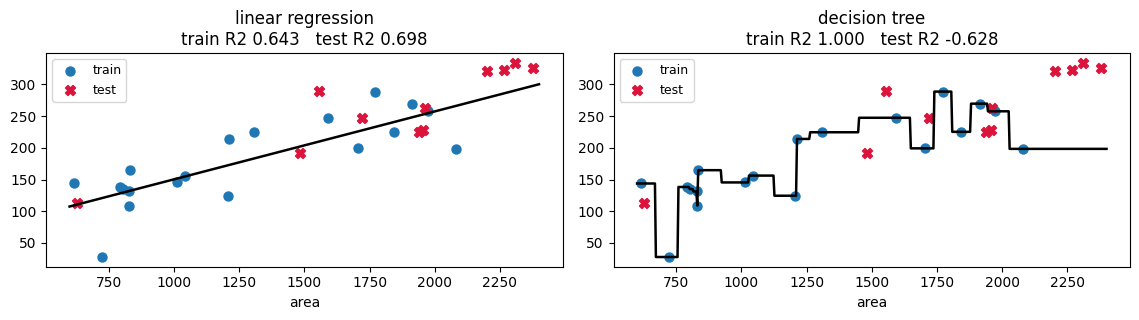

In [15]:
grid = np.linspace(600, 2400, 500).reshape(-1, 1)
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.3))
for ax, m, name in [(axes[0], LinearRegression().fit(X_tr, y_tr), "linear regression"),
                    (axes[1], DecisionTreeRegressor(random_state=0).fit(X_tr, y_tr), "decision tree")]:
    ax.plot(grid, m.predict(grid), color="black", lw=1.8)
    ax.scatter(X_tr, y_tr, s=42, label="train")
    ax.scatter(X_te, y_te, s=52, marker="X", color="crimson", label="test")
    ax.set_title(f"{name}\ntrain R2 {m.score(X_tr, y_tr):.3f}   test R2 {m.score(X_te, y_te):.3f}")
    ax.legend(fontsize=9); ax.set_xlabel("area")
plt.tight_layout(); plt.show()

Look at the right-hand picture. The tree's line passes through **every single blue dot
exactly** — that is the 1.000 — and it is a staircase of nonsense in between, which is why
the red crosses are nowhere near it.

This failure is called **overfitting**, and it is the central problem of the whole module.
Almost every technique you learn from here on is, in some way, a defence against it.

> **The rule: hide 20–30% of your rows before you start, and never let the model or anything
> else touch them until you are ready to be graded.**

---
# 4 · Features, and why models cannot read words

## 4.1 · Every column is one of these

| family | kind | examples | can a model use it directly? |
|---|---|---|---|
| **numeric** | continuous | price, area, 3.7 kg | ✅ yes |
| **numeric** | discrete count | bedrooms, clicks, 3 cars | ✅ yes |
| **categorical** | **nominal** — no order | city, colour, brand, blood type | ❌ must be encoded |
| **categorical** | **ordinal** — real order | S < M < L, bronze < silver < gold | ❌ must be encoded |
| other | binary | yes/no, true/false | ✅ as 0/1 |
| other | text, date, image | reviews, 2026-10-18, photos | own techniques, later |

The distinction that matters today is **nominal vs ordinal**:

- **Nominal** — the categories have **no order**. Boston is not more or less than Miami.
- **Ordinal** — they genuinely **do** have an order. Small really is less than Large.

Getting that call wrong is the mistake in section 5, and it costs real accuracy.

## 4.2 · Why you cannot just hand over the word

In [ ]:
houses2 = houses.copy()
rng5 = np.random.default_rng(1)
houses2["city"] = rng5.choice(["Boston", "Austin", "Denver"], len(houses2))
print(houses2.head(3))

try:
    LinearRegression().fit(houses2[["area", "city"]], houses2["price"])
except ValueError as e:
    print("\nValueError:", e)

This is **not** a software limitation somebody could patch. It is what the model *is*.

Every model in this course multiplies its inputs by weights and adds them up:

$$\hat{y} \;=\; w_1 x_1 \;+\; w_2 x_2 \;+\; \ldots \;+\; b$$

There is no sensible value for `"Boston" × 0.4`. So every categorical column has to become
numbers before training — and **how** you turn it into numbers changes the answer. That is
the rest of this session.

---
# 5 · Encoding categorical data

Let us build a dataset where we **know the truth**, so we can check whether each encoding
recovers it. Five cities, each with a real effect on price that we put there ourselves.

In [ ]:
rng = np.random.default_rng(3110)
n = 600
cities = ["Boston", "Austin", "Denver", "Miami", "Seattle"]
TRUE_EFFECT = {"Boston": 120, "Austin": 40, "Denver": 65, "Miami": 95, "Seattle": 80}

city = rng.choice(cities, n)
area = rng.uniform(600, 2400, n)
price = np.array([30 + 0.09*a + TRUE_EFFECT[c] for a, c in zip(area, city)]) + rng.normal(0, 15, n)

df = pd.DataFrame({"area": area, "city": city, "price": price})
print(df.head())
print("\ncity is NOMINAL - there is no order between Boston and Miami")
print("true city effects (we built these in):", TRUE_EFFECT)

## 5.1 · ⚠️ Label encoding — the obvious idea, and why it is wrong

The first thing anyone tries: give each city a number.

In [ ]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["city_label"] = le.fit_transform(df["city"])
print("the mapping it chose (alphabetical):")
for c, i in zip(le.classes_, range(len(le.classes_))):
    print(f"   {c:<8} -> {i}")
print("\n", df[["city", "city_label"]].drop_duplicates().sort_values("city_label").to_string(index=False))

Now think about what a linear model does with that column. It multiplies it by a weight:

$$\text{price} \;=\; \ldots \;+\; w \times \text{city\_label}$$

With Austin = 0, Boston = 1, Denver = 2, Miami = 3, Seattle = 4, the model is **forced to
believe** that Denver is twice Boston, and Seattle is four times it, and that the step from
Austin to Boston is exactly the same size as the step from Miami to Seattle.

None of that is true. The numbers are just alphabetical order.

## 5.2 · One-hot encoding — the right default

Give each category **its own yes/no column**. Each row has exactly one `1` — that is where
the name comes from.

In [ ]:
small = pd.DataFrame({"city": ["Boston", "Austin", "Miami", "Austin"]})
print("before:"); print(small)
print("\nafter:")
print(pd.get_dummies(small, columns=["city"]).astype(int))

No category is bigger than any other, so no false order can be invented. And the model gets
to learn a **completely separate adjustment** for each city, instead of being forced to put
them all on one straight line.

Now let us measure whether it actually matters.

In [ ]:
# Same data, same model, same split - ONLY the encoding differs
onehot = pd.get_dummies(df[["area", "city"]], columns=["city"]).astype(float)

X_tr_i, X_te_i, y_tr, y_te = train_test_split(df.index, df.price, test_size=0.3, random_state=11)

m_label = LinearRegression().fit(df.loc[X_tr_i, ["area", "city_label"]], y_tr)
p_label = m_label.predict(df.loc[X_te_i, ["area", "city_label"]])

m_onehot = LinearRegression().fit(onehot.loc[X_tr_i], y_tr)
p_onehot = m_onehot.predict(onehot.loc[X_te_i])

print(f"{'encoding':<18} {'avg error ($000)':>17} {'R2':>8}")
print("-"*46)
print(f"{'label':<18} {mean_absolute_error(y_te, p_label):>17.2f} {r2_score(y_te, p_label):>8.3f}")
print(f"{'one-hot':<18} {mean_absolute_error(y_te, p_onehot):>17.2f} {r2_score(y_te, p_onehot):>8.3f}")

**The wrong encoding doubled the error**, from $11,150 to $23,330 per house. Nothing else
about the model changed.

Look at what the label-encoded model was forced to learn:

In [ ]:
print(f"label model's city coefficient: {m_label.coef_[1]:+.2f} per 'unit of city'")
print("   i.e. it had to assume each step up the alphabet is worth the same amount.")

## 5.3 · Did one-hot actually recover the truth?

Because we built this data ourselves, we can check. One subtlety first: the model's
**intercept** soaks up the overall average, so the raw coefficients are shifted by a
constant. What is meaningful is the **gap between cities**.

In [ ]:
city_cols = [c for c in onehot.columns if c.startswith("city_")]
learned = dict(zip([c.replace("city_", "") for c in city_cols], m_onehot.coef_[1:]))
base = "Austin"

print(f"{'city':<9} {'learned gap vs Austin':>22} {'true gap':>10}")
print("-"*45)
for c in ["Austin", "Denver", "Seattle", "Miami", "Boston"]:
    print(f"{c:<9} {learned[c] - learned[base]:>+22.2f} "
          f"{TRUE_EFFECT[c] - TRUE_EFFECT[base]:>+10d}")

Every city within a few thousand dollars of its true effect. The model worked out five
separate city premiums from nothing but those five 0/1 columns.

## 5.4 · The dummy variable trap — and what it really costs

If a house is not Austin, not Denver, not Miami and not Seattle, it must be Boston. The
fifth column tells you nothing the other four did not. Worse, the five dummies add to
exactly **1** in every row — which is precisely what the model's intercept already is.

In [ ]:
print("the five dummies sum to 1 in every row:",
      bool((onehot[city_cols].sum(axis=1) == 1).all()))

X_with_intercept = np.column_stack([np.ones(n), onehot.values])
X_dropped        = np.column_stack([np.ones(n), onehot.drop(columns=city_cols[0]).values])
print(f"\nintercept + all 5 dummies : {X_with_intercept.shape[1]} columns, "
      f"rank {np.linalg.matrix_rank(X_with_intercept)}  <- RANK DEFICIENT")
print(f"intercept + 4 dummies     : {X_dropped.shape[1]} columns, "
      f"rank {np.linalg.matrix_rank(X_dropped)}  <- fine")

In [ ]:
# Does it actually break the predictions?  Let us check rather than assume.
dropped = pd.get_dummies(df[["area", "city"]], columns=["city"], drop_first=True).astype(float)
m_drop = LinearRegression().fit(dropped.loc[X_tr_i], y_tr)

print(f"all 5 dummies : test error {mean_absolute_error(y_te, p_onehot):.4f}")
print(f"4 dummies     : test error {mean_absolute_error(y_te, m_drop.predict(dropped.loc[X_te_i])):.4f}")

**Identical to four decimal places.** This is worth being precise about, because most
tutorials overstate it:

- It does **not** break your predictions in scikit-learn. The solver quietly picks one of
  the infinitely many equivalent answers and gets on with it.
- It **does** break **interpretation** — the coefficients are no longer unique, so reading
  them means nothing. Any constant can shift between the intercept and the dummies.
- It **does** break **classical OLS** (statsmodels, and anything that inverts XᵀX), because
  that matrix is now singular. The condition number here is about 7.9 × 10¹⁸.

**Practical rule:** use `drop_first=True` when you plan to read coefficients or use
statsmodels. For a tree or a random forest it genuinely does not matter.

## 5.5 · Ordinal encoding — when the order IS real

Sometimes the categories really are ranked, and 0, 1, 2, 3 is not a lie — it is the truth,
and it costs one column instead of four.

In [ ]:
rng6 = np.random.default_rng(3120)
m = 500
levels = ["High School", "Bachelor", "Master", "PhD"]
order  = {lvl: i for i, lvl in enumerate(levels)}

def salary_experiment(bumps, seed):
    r = np.random.default_rng(seed)
    edu = r.choice(levels, m, p=[.35, .35, .2, .1])
    yrs = r.uniform(0, 20, m)
    sal = np.array([30 + bumps[e] + 1.5*y for e, y in zip(edu, yrs)]) + r.normal(0, 6, m)
    d = pd.DataFrame({"edu": edu, "yrs": yrs, "salary": sal})
    d["edu_ord"] = d.edu.map(order)
    oh = pd.get_dummies(d[["yrs", "edu"]], columns=["edu"]).astype(float)
    tr, te = train_test_split(d.index, test_size=0.3, random_state=3)
    m1 = LinearRegression().fit(d.loc[tr, ["yrs", "edu_ord"]], d.loc[tr, "salary"])
    m2 = LinearRegression().fit(oh.loc[tr], d.loc[tr, "salary"])
    return (mean_absolute_error(d.loc[te, "salary"], m1.predict(d.loc[te, ["yrs", "edu_ord"]])),
            mean_absolute_error(d.loc[te, "salary"], m2.predict(oh.loc[te])))

even   = salary_experiment({"High School": 0, "Bachelor": 8, "Master": 16, "PhD": 24}, 3120)
uneven = salary_experiment({"High School": 0, "Bachelor": 6, "Master": 9,  "PhD": 34}, 3121)

print(f"{'true gaps':<24} {'ordinal':>9} {'one-hot':>9}")
print("-"*45)
print(f"{'even (0, 8, 16, 24)':<24} {even[0]:>9.2f} {even[1]:>9.2f}")
print(f"{'uneven (0, 6, 9, 34)':<24} {uneven[0]:>9.2f} {uneven[1]:>9.2f}")

**The rule that follows from those two rows:**

- When the spacing really is **even**, ordinal ties one-hot exactly (4.98 vs 4.97) and uses
  a quarter of the columns. Use it.
- When the spacing is **uneven**, ordinal is about 30% worse (6.04 vs 4.64), because it is
  forced to put all four levels on one straight line and the real jump to PhD is nothing
  like the others.

⚠️ So "there is an order" is **not** enough to justify ordinal encoding. It also assumes the
gaps are roughly equal. If you are unsure, one-hot is the safe choice — it assumes nothing.

Note also that the ordinal map is something **you write by hand**. That is a feature, not a
chore: it forces you to state the order you believe in, rather than letting `LabelEncoder`
invent one alphabetically.

## 5.6 · ⚠️ When one-hot is the wrong answer: too many categories

In [ ]:
rng7 = np.random.default_rng(7)
N = 1000
zipcode = rng7.integers(10000, 10800, N).astype(str)
print(f"{N} rows, zip code has {len(set(zipcode))} unique values")
print(f"one-hot would create {len(set(zipcode))} columns from {N} rows")
print("\n-> almost every column is zero almost everywhere,")
print("   and the model has nearly as many knobs as examples. It will memorise.")

In [ ]:
# The simplest fix: keep the common ones, bucket the rest
s = pd.Series(zipcode)
top = s.value_counts().head(20).index
grouped = s.where(s.isin(top), "Other")
print(f"after grouping: {grouped.nunique()} categories instead of {s.nunique()}")
print(grouped.value_counts().head(5))
print(f"...\n'Other' absorbs {(grouped == 'Other').sum()} of the {N} rows")

**Your options when a column has hundreds of categories:**

| option | what it does |
|---|---|
| group rare → `"Other"` | keep the top *k*, bucket the rest. Simplest, usually enough. |
| **frequency encoding** | replace each category by how often it appears. One column. |
| **target encoding** | replace it by the average label for that category. One column, powerful, **dangerous** — see next. |
| a model that handles categories natively | CatBoost, LightGBM |

## 5.7 · ⚠️ Fit the encoder on TRAIN only

This is the most important line in the whole session, and it is the easiest to get wrong.

Below there is **no relationship at all** between the category and the target — the data is
pure noise. We build the same model twice: once fitting the target encoder on everything,
once fitting it on the training rows only.

In [ ]:
print(f"{'categories':>11} | {'LEAK: fitted on all':>21} | {'CLEAN: fitted on train':>23}")
print("-"*62)
for k in [8, 40, 100, 200]:
    r = np.random.default_rng(42); N = 400
    cat = r.integers(0, k, N).astype(str)
    yv  = r.normal(0, 1, N)                       # NO signal whatsoever
    d = pd.DataFrame({"cat": cat, "y": yv})
    tr, te = train_test_split(d, test_size=0.3, random_state=1)
    gmean = d.y.mean()

    scores = []
    for mapping in [d.groupby("cat").y.mean(),        # LEAK: uses test rows' own answers
                    tr.groupby("cat").y.mean()]:      # CLEAN: train only
        a = tr.cat.map(mapping).fillna(gmean)
        b = te.cat.map(mapping).fillna(gmean)
        mod = LinearRegression().fit(a.values.reshape(-1, 1), tr.y)
        scores.append(mod.score(b.values.reshape(-1, 1), te.y))
    print(f"{k:>11} | {scores[0]:>+21.3f} | {scores[1]:>+23.3f}")

Read the bottom row. With 200 categories, the leaky version reports a **test R² of +0.384**
— which looks like a genuine, publishable finding — on data that contains **nothing at
all**. The clean version reports −0.536 and is correctly telling you the model is worthless.

**The honest answer looks like failure and the leaky answer looks like success.** That is
exactly why this mistake survives in real projects.

What went wrong mechanically: the target encoder computed each category's average `y`
*using the test rows too*. So every test row's own answer was baked into its own feature
before the model ever saw it. The model is partly reading the answer sheet.

> **The rule: anything that LEARNS something from the data — an encoder, a scaler, an
> imputer — is fitted on the training set and merely applied to the test set.** Never the
> other way round, and never on both at once.

`sklearn.pipeline.Pipeline` exists mainly to make this impossible to get wrong, and we will
use it from Day 33 onwards.

## 5.8 · Which encoder, and when

| Your column | Use | Code |
|---|---|---|
| Nominal, under ~15 categories | **one-hot** | `pd.get_dummies(df, columns=[c])` |
| Nominal, and you will read coefficients | one-hot, drop one | `pd.get_dummies(…, drop_first=True)` |
| Ordinal, gaps roughly even | **ordinal** — map by hand | `df[c].map({"S":0, "M":1, "L":2})` |
| Ordinal, gaps clearly uneven | one-hot (safer) | `pd.get_dummies(df, columns=[c])` |
| Nominal, hundreds of categories | group rare → Other, then one-hot | `value_counts()` then `.where()` |
| Still too many after grouping | frequency or target encoding | `df[c].map(df[c].value_counts())` |
| The **label** of a classifier | label encoding **is correct here** | `LabelEncoder().fit_transform(y)` |

**Two rules cover almost everything:** when in doubt, **one-hot** — it assumes nothing. And
whatever you choose, **fit it on train only**.

The last row is the exception worth memorising: `LabelEncoder` is the right tool for the
thing you are *predicting*, and the wrong tool for the things you predict *from*.

---
# 6 · Putting it together

One function that takes a raw dataframe and returns model-ready arrays, in the right order,
without leaking.

In [ ]:
def prepare(df, label, ordinal_maps=None, max_cats=15, test_size=0.25, random_state=42):
    """Split first, then encode. Returns X_train, X_test, y_train, y_test."""
    ordinal_maps = ordinal_maps or {}
    y = df[label]
    X = df.drop(columns=[label])

    #  1. SPLIT FIRST - nothing after this may learn from the test rows
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state)
    X_tr, X_te = X_tr.copy(), X_te.copy()

    #  2. ordinal columns: a map YOU wrote, so the order is intentional
    for col, mapping in ordinal_maps.items():
        X_tr[col] = X_tr[col].map(mapping)
        X_te[col] = X_te[col].map(mapping)

    #  3. group rare categories, using TRAIN counts only
    cats = X_tr.select_dtypes(include="object").columns
    for col in cats:
        keep = X_tr[col].value_counts().head(max_cats).index
        X_tr[col] = X_tr[col].where(X_tr[col].isin(keep), "Other")
        X_te[col] = X_te[col].where(X_te[col].isin(keep), "Other")

    #  4. one-hot, then align so both frames have exactly the same columns
    X_tr = pd.get_dummies(X_tr, columns=list(cats)).astype(float)
    X_te = pd.get_dummies(X_te, columns=list(cats)).astype(float)
    X_te = X_te.reindex(columns=X_tr.columns, fill_value=0.0)
    return X_tr, X_te, y_tr, y_te

In [ ]:
# A dataset with a numeric, a nominal and an ordinal column
rng8 = np.random.default_rng(99)
k = 400
demo2 = pd.DataFrame({
    "area":  rng8.uniform(600, 2400, k).round(0),
    "city":  rng8.choice(["Boston", "Austin", "Denver", "Miami"], k),
    "grade": rng8.choice(["low", "medium", "high"], k),
})
demo2["price"] = (30 + 0.09*demo2.area
                  + demo2.city.map({"Boston": 120, "Austin": 40, "Denver": 65, "Miami": 95})
                  + demo2.grade.map({"low": 0, "medium": 15, "high": 30})
                  + rng8.normal(0, 12, k))

X_tr, X_te, y_tr, y_te = prepare(
    demo2, label="price",
    ordinal_maps={"grade": {"low": 0, "medium": 1, "high": 2}})

print("before:", demo2.shape, "->", list(demo2.columns))
print("after :", X_tr.shape, "->", list(X_tr.columns))
print(f"\n{len(X_tr)} training rows, {len(X_te)} test rows")

In [ ]:
model = LinearRegression().fit(X_tr, y_tr)
print(f"train R2 {model.score(X_tr, y_tr):.3f}")
print(f"test  R2 {model.score(X_te, y_te):.3f}   <- the one that counts")
print(f"average error on unseen houses: ${mean_absolute_error(y_te, model.predict(X_te)):.2f}k")

Train and test scores are close, which is what a healthy model looks like. A large gap
between them is the warning sign from section 3.

The one line people always forget is `reindex`: if a city appears in the test set but not in
the training set, one-hot produces a column in `X_te` that `X_tr` does not have, and
`.predict()` crashes. Aligning the columns and filling with zero is the fix.

In real projects a `sklearn.pipeline.Pipeline` does all of this and refuses to let you leak.
We built it by hand first so you know what it is doing.

---
# Recap — today in twelve lines

1. ⭐ Traditional code: **rules + data → answers**. Machine learning: **data + answers → rules**.
2. **sample** = a row · **feature** = an input column (X) · **label** = the answer column (y).
3. "Learning" = try numbers, measure the error, keep the best. There is no magic in it.
4. **Supervised**: the answers come with the data. About 90% of industry work.
5. **Regression** = the label is a number. **Classification** = the label is a category.
6. **Unsupervised**: no answers — cluster the rows, or shrink the columns. No accuracy score exists.
7. **Reinforcement**: no answers, but the world pays a reward. Not covered further here.
8. ⚠️ A decision tree scored **R² = 1.000** on its training data and **−0.628** on new data.
9. ⚠️ Models do arithmetic, so every word column must be **encoded** before training.
10. ⚠️ Label-encoding a nominal column **doubled the error**: $11.15k → $23.33k.
11. **One-hot** gives each category its own 0/1 column. No invented order. The safe default.
12. ⚠️ **Split first, fit encoders on train only** — or your test score is a lie (+0.38 R² on pure noise).

## Homework

- Take your Day 21 dataset. List every column and label it numeric / nominal / ordinal.
- Say what a supervised problem on it would predict, and whether that is regression or
  classification.
- Run `prepare()` on it and report the shape before and after.

### Next class — Topics 3.3 + 3.4: feature scaling and feature engineering
Why a column measured in thousands drowns out one measured in units, what to do about it,
and how to build features that were not in the data you were given.

---
*Slides & notebooks by Srinivasa Sai Chava · Boston University*